# Milestone 4, Part 1.4: Drift + continual update experiment

We start from our deployed model **v2 + input sanitizer** (end of Milestone 3) and replay the test months (May to Oct 2026)
one month at a time. Each month is first scored by the model that is serving (it has not seen that month), then the model
may update using the continual learning module (`src/continual.py`: replay buffer, triggers, accept/reject gate, model registry).

- **A. Real stream**: the real months, no added drift.
- **B. Simulated drift**: the typo rate grows from 0% to 30% of letters over the six months.
- **C. Bad labels**: one update where some labels are wrong (simulated annotator mistakes).
- **D. Latency and size** of the updated models.

All runs that train use 3 seeds (6450, 6451, 6452) and we report mean ± std.
The code is in `src/m4_experiment.py`. Running it takes about 30 min on our laptop (Apple M4 Max), so this notebook
loads the saved results by default. Set `RUN = True` to run everything again.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RUN = False        # True = run the whole experiment again (about 30 min)
OUT = Path('outputs/milestone4/experiment')
if RUN:
    subprocess.run([sys.executable, '-m', 'src.m4_experiment'], check=True)
else:
    subprocess.run([sys.executable, '-m', 'src.m4_experiment', '--report'], check=True, capture_output=True)

pd.set_option('display.precision', 3)
summary = pd.read_csv(OUT / 'summary.csv')
logs = pd.read_csv(OUT / 'stream_logs_all.csv', dtype={'month': str})
steps = logs[logs.step > 0].copy()
info = json.load(open(OUT / 'runs' / 'B_always_replay_6450' / 'run_info.json'))
print('device:', info['device'], '| torch', info['torch'])
print('continual learning settings:', {k: info['cfg'][k] for k in ['replay_ratio', 'buffer_size', 'holdout_frac',
      'min_new_pairs', 'epochs', 'aug_prob', 'gate_tol_new', 'gate_tol_old', 'psi_limit', 'f1_drop', 'prior_change']})
print('training settings (Milestone 2):', {k: info['train_cfg'][k] for k in ['batch_size', 'learning_rate', 'weight_decay', 'warmup_ratio', 'margin']})

device: mps | torch 2.15.0
continual learning settings: {'replay_ratio': 1.0, 'buffer_size': 4000, 'holdout_frac': 0.2, 'min_new_pairs': 200, 'epochs': 2, 'aug_prob': 0.5, 'gate_tol_new': 0.0, 'gate_tol_old': 0.01, 'psi_limit': 0.2, 'f1_drop': 0.03, 'prior_change': 0.1}
training settings (Milestone 2): {'batch_size': 32, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'warmup_ratio': 0.1, 'margin': 0.5}


## A. Real stream (May to Oct 2026)

Three choices: never update, update every month (replay + gate), or update only when a Milestone 3 trigger fires.

In [2]:
cols = ['strategy', 'seeds', 'f1_mean', 'f1_std', 'pr_auc_mean', 'card_ari_mean', 'card_ari_std',
        'old_val_f1_end_mean', 'updates_accepted', 'updates_rejected', 'update_min_total_mean']
summary[summary.part == 'A'][cols]

,strategy,seeds,f1_mean,f1_std,pr_auc_mean,card_ari_mean,card_ari_std,old_val_f1_end_mean,updates_accepted,updates_rejected,update_min_total_mean
0,no update,1,0.895,NaN,0.967,0.814,NaN,0.878,0.0,0.0,0.000
1,replay + gate (monthly),3,0.898,0.005,0.965,0.795,0.005,0.878,3.0,2.0,0.409
2,replay + gate (when triggered),3,0.895,0.000,0.967,0.814,0.000,0.878,0.0,0.0,0.000


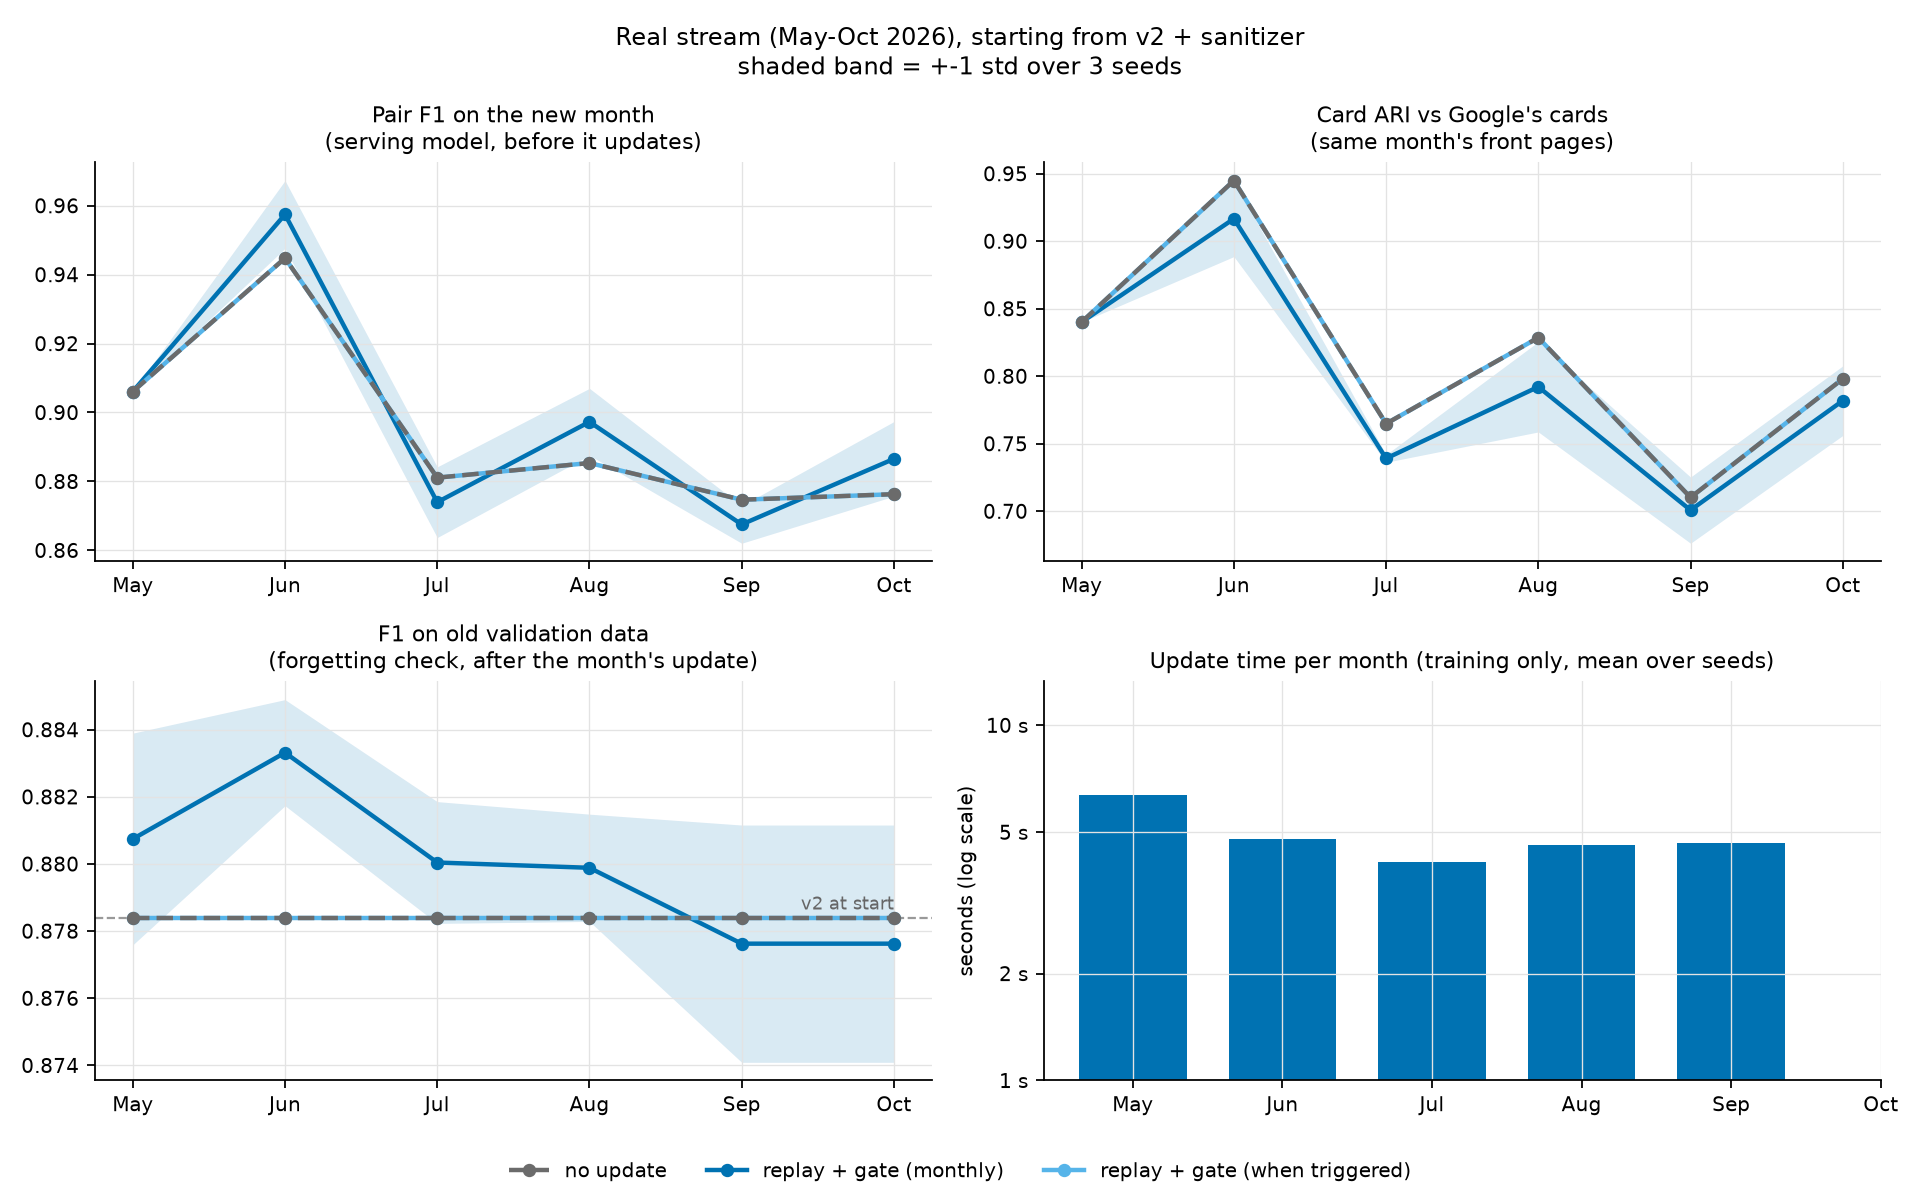

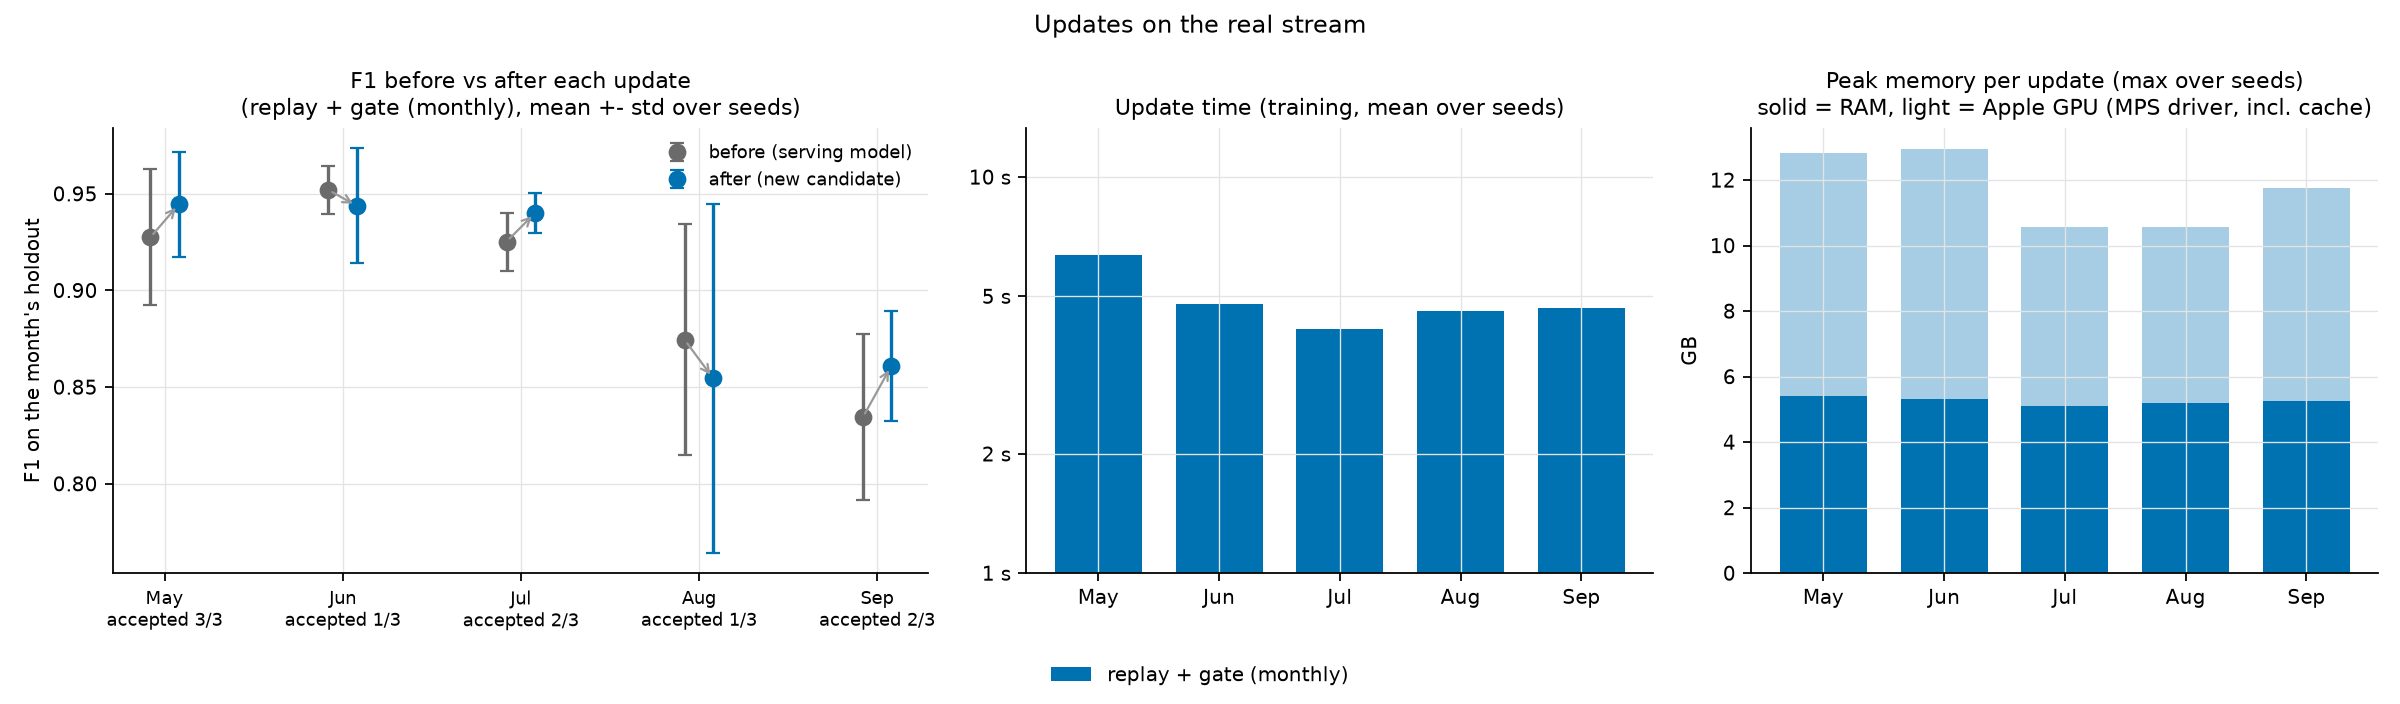

In [3]:
display(Image(OUT / 'figures' / 'A_trajectories.png'))
display(Image(OUT / 'figures' / 'A_updates.png'))

No trigger fired in any month (same as Milestone 3), so "when triggered" is the same as "no update".
Updating every month anyway gives almost the same F1 and a slightly lower card ARI, so on the real data there was no
need to update.

## B. Simulated drift: typos grow from 0% to 30%

Same months, but every headline gets more typos each month (same typo function as the Milestone 3 stress tests).
We compare five strategies. Full retrain is slow, so it was run with one seed only.

In [4]:
summary[summary.part == 'B'][cols + ['last_f1_mean', 'last_f1_std']]

,strategy,seeds,f1_mean,f1_std,pr_auc_mean,card_ari_mean,card_ari_std,old_val_f1_end_mean,updates_accepted,updates_rejected,update_min_total_mean,last_f1_mean,last_f1_std
3,no update,1,0.869,NaN,0.949,0.757,NaN,0.878,0.000,0.000,0.000,0.823,NaN
4,"fine-tune, no replay",3,0.872,0.004,0.949,0.776,0.020,0.882,4.333,0.667,0.273,0.842,0.020
5,replay + gate (monthly),3,0.882,0.006,0.948,0.762,0.017,0.878,2.333,2.667,0.407,0.861,0.015
6,replay + gate (when triggered),3,0.872,0.003,0.950,0.755,0.012,0.876,2.667,0.667,0.253,0.845,0.020
7,full retrain (monthly),1,0.885,NaN,0.950,0.765,NaN,0.878,4.000,1.000,10.089,0.874,NaN


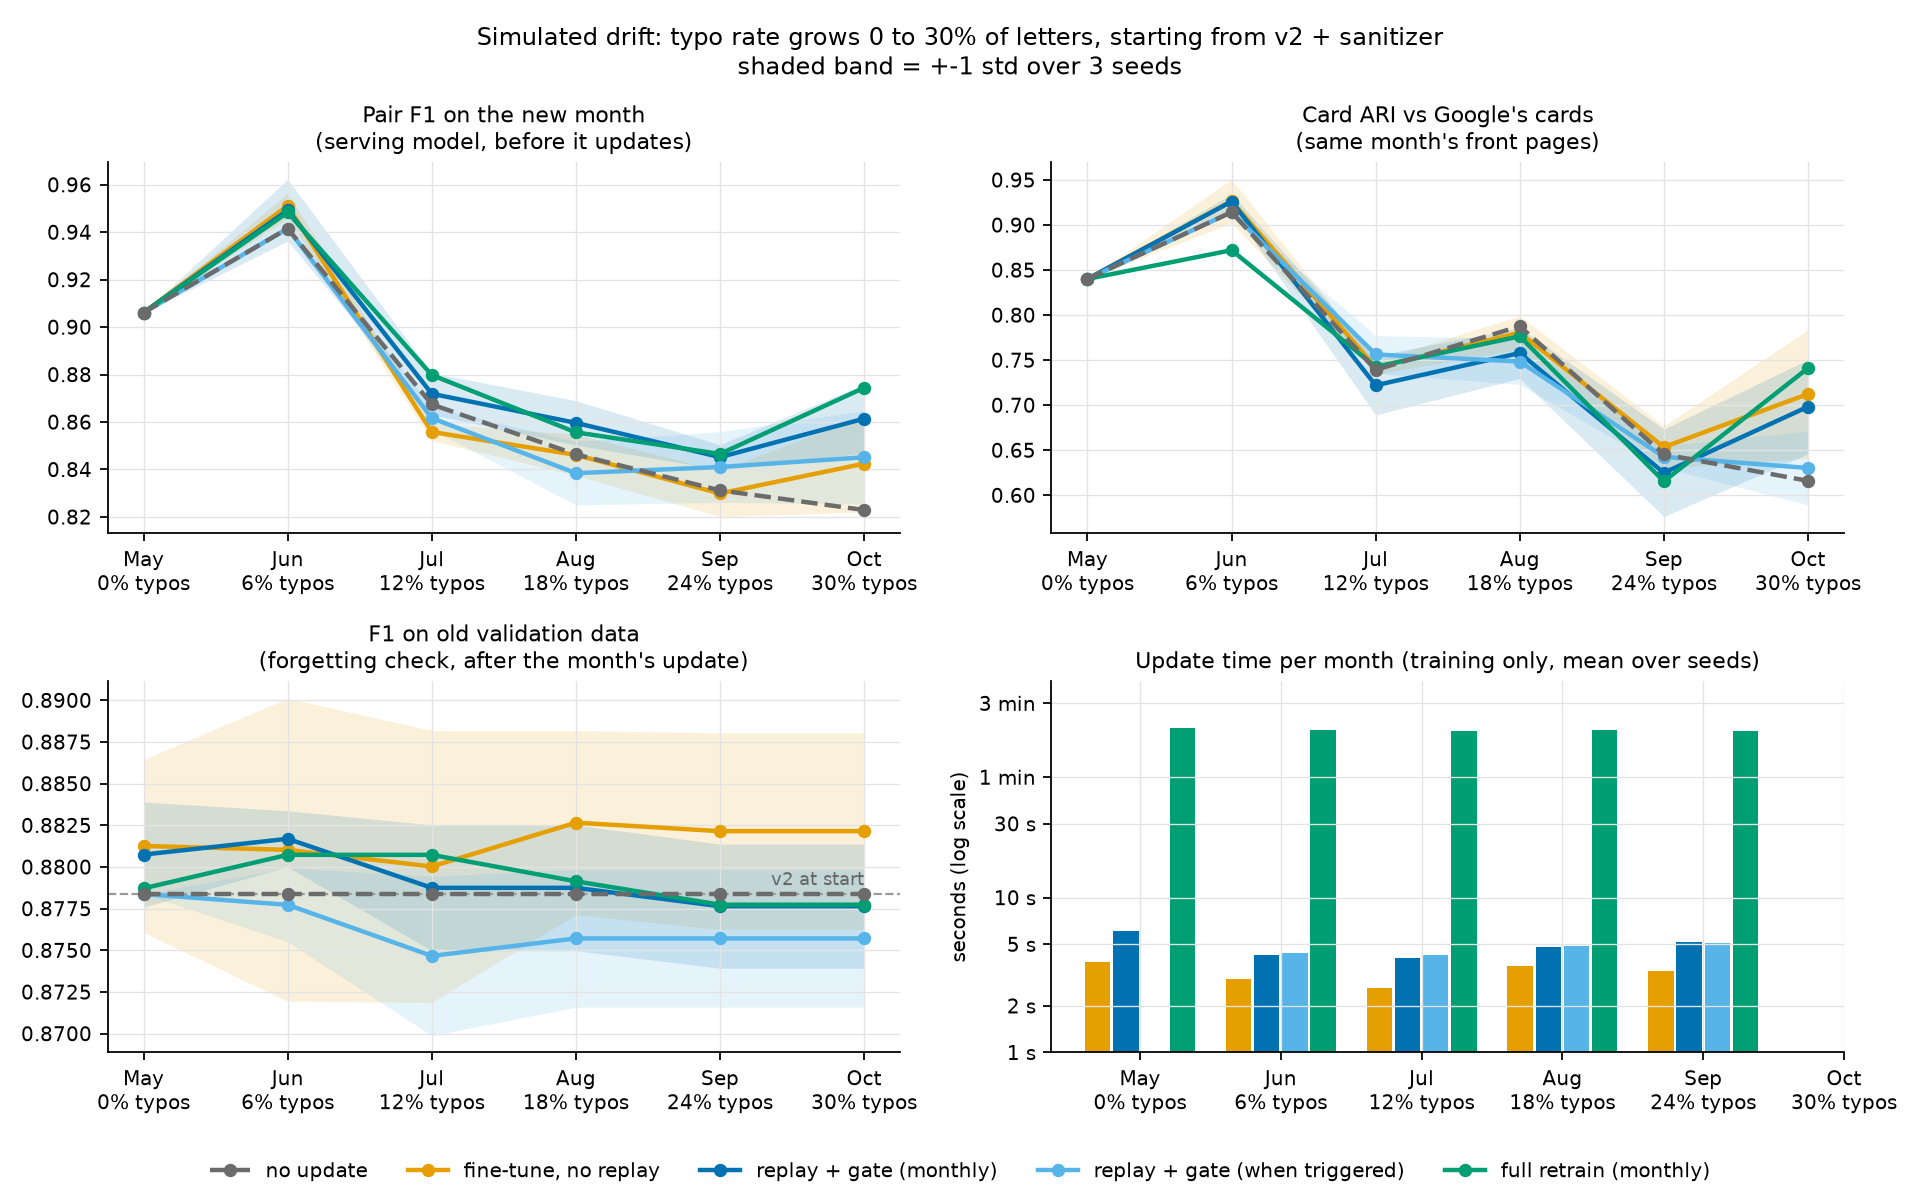

In [5]:
display(Image(OUT / 'figures' / 'B_trajectories.png'))

**Before and after each update** (our method, replay + gate every month, mean over 3 seeds).
`holdout F1 before/after` = the serving model vs the new candidate on 20% of the month's front pages that were kept out of training.
`old F1` = the same on the old validation data (forgetting check). October has too few pairs to train on, so it is skipped.

In [6]:
r = steps[(steps.part == 'B') & (steps.strategy == 'replay + gate (monthly)')]
per_update = r.groupby('batch').agg(
    month_F1_before=('before_f1', 'mean'),
    holdout_F1_before=('new_f1_current', 'mean'), holdout_F1_after=('new_f1_candidate', 'mean'),
    old_F1_before=('old_f1_current', 'mean'), old_F1_after=('old_f1_candidate', 'mean'),
    accepted=('decision', lambda d: f"{(d == 'accepted').sum()}/{len(d)}"),
    update_sec=('update_minutes', lambda m: m.mean() * 60),
    peak_ram_gb=('peak_ram_mb', lambda m: m.max() / 1000), peak_gpu_gb=('peak_vram_mb', lambda m: m.max() / 1000))
per_update

,month_F1_before,holdout_F1_before,holdout_F1_after,old_F1_before,old_F1_after,accepted,update_sec,peak_ram_gb,peak_gpu_gb
batch,,,,,,,,,
202605 (typos 0.00),0.906,0.927,0.944,0.879,0.881,3/3,6.098,4.768,11.411
202606 (typos 0.06),0.949,0.952,0.960,0.884,0.885,2/3,4.272,4.717,9.037
202607 (typos 0.12),0.872,0.901,0.905,0.886,0.883,1/3,4.067,4.647,7.032
202608 (typos 0.18),0.860,0.864,0.848,0.885,0.884,0/3,4.789,4.817,9.213
202609 (typos 0.24),0.845,0.854,0.834,0.884,0.884,1/3,5.182,4.904,10.563
202610 (typos 0.30),0.861,NaN,NaN,NaN,NaN,0/3,NaN,NaN,NaN


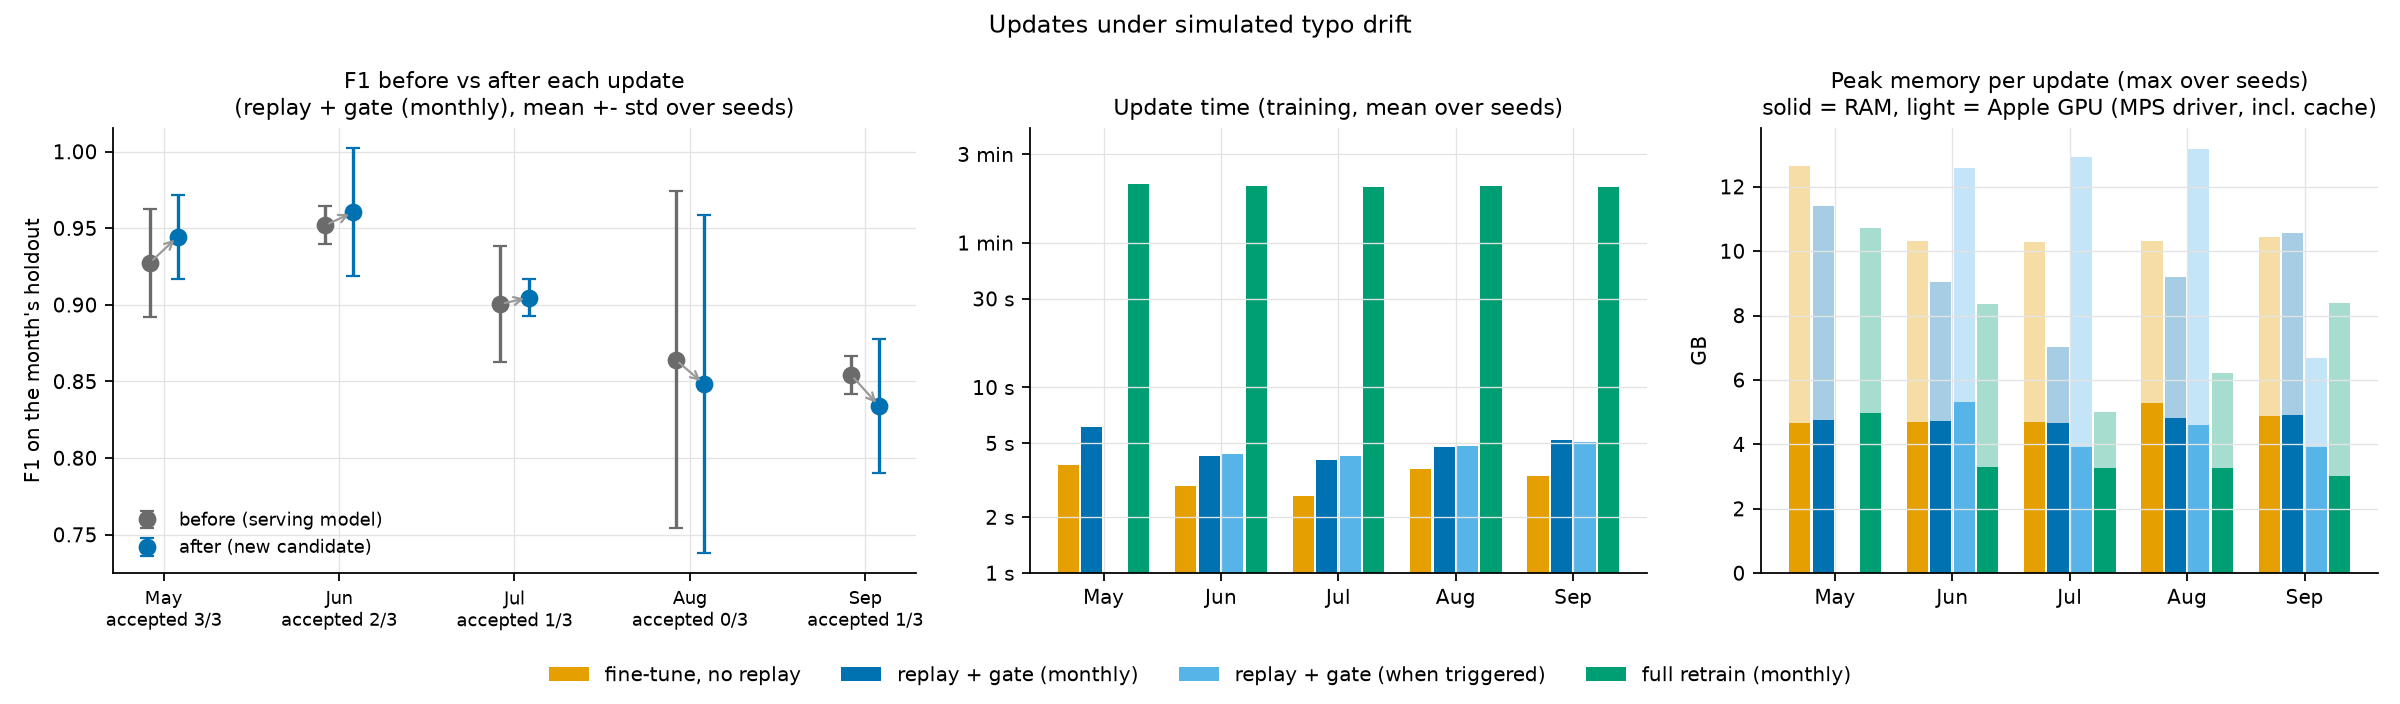

In [7]:
display(Image(OUT / 'figures' / 'B_updates.png'))

Left: F1 on the month's holdout before (serving model) and after (new candidate) each update; the gate only accepts the
candidate if it is not worse. The holdout is different for each seed, so the error bars are wide.
Middle and right: update time and peak memory for every strategy that trains.

Which triggers fired in the "when triggered" runs (seed 6450). T1 = data drift (PSI > 0.2 on 2 of 4 features),
T2 = F1 drop, T3 = change in the share of same-story pairs.

In [8]:
t = steps[(steps.part == 'B') & (steps.strategy == 'replay + gate (when triggered)') & (steps.seed == 6450)]
t[['batch', 'psi_score', 'psi_oov', 'psi_words', 'psi_edition', 'T1_data_drift', 'T2_perf_drop', 'T3_balance_change', 'decision']]

,batch,psi_score,psi_oov,psi_words,psi_edition,T1_data_drift,T2_perf_drop,T3_balance_change,decision
106,202605 (typos 0.00),0.113,0.109,0.139,8.502e-03,False,False,False,no update
107,202606 (typos 0.06),0.059,0.289,0.195,4.374e+00,True,False,False,accepted
108,202607 (typos 0.12),0.094,0.801,0.142,2.632e-01,True,False,False,rejected
109,202608 (typos 0.18),0.063,0.808,0.036,7.120e-01,True,False,False,accepted
110,202609 (typos 0.24),0.187,1.608,0.127,1.922e-01,False,False,False,no update
111,202610 (typos 0.30),0.323,2.261,0.152,9.608e-05,True,True,False,skipped (too few new pairs)


## C. Bad labels

If humans label new pairs (Part 2), some labels will be wrong. We take May to Jul as the newly labelled batch, make some
labels wrong, run one replay update and check the result on clean Aug to Oct pairs.
- **random**: any label is flipped.
- **missed**: the annotator misses that two headlines are the same story (1 becomes 0).

In [9]:
bad = pd.read_csv(OUT / 'bad_labels_summary.csv')
bad[['kind', 'flip_rate', 'flipped', 'gate_accept', 'future_f1_mean', 'future_f1_std', 'future_ari_mean', 'v2_future_f1', 'v2_future_ari']]

,kind,flip_rate,flipped,gate_accept,future_f1_mean,future_f1_std,future_ari_mean,v2_future_f1,v2_future_ari
0,missed,0.1,65.333,1.000,0.877,0.013,0.748,0.879,0.773
1,missed,0.2,127.667,0.667,0.869,0.015,0.736,0.879,0.773
2,missed,0.3,192.667,0.667,0.866,0.002,0.732,0.879,0.773
3,missed,0.4,265.333,1.000,0.858,0.011,0.725,0.879,0.773
4,none,0.0,0.000,1.000,0.873,0.003,0.769,0.879,0.773
5,random,0.1,130.333,0.667,0.882,0.009,0.760,0.879,0.773
6,random,0.2,278.333,0.000,0.871,0.015,0.767,0.879,0.773
7,random,0.3,423.000,0.667,0.881,0.005,0.765,0.879,0.773
8,random,0.4,562.667,0.333,0.869,0.005,0.770,0.879,0.773


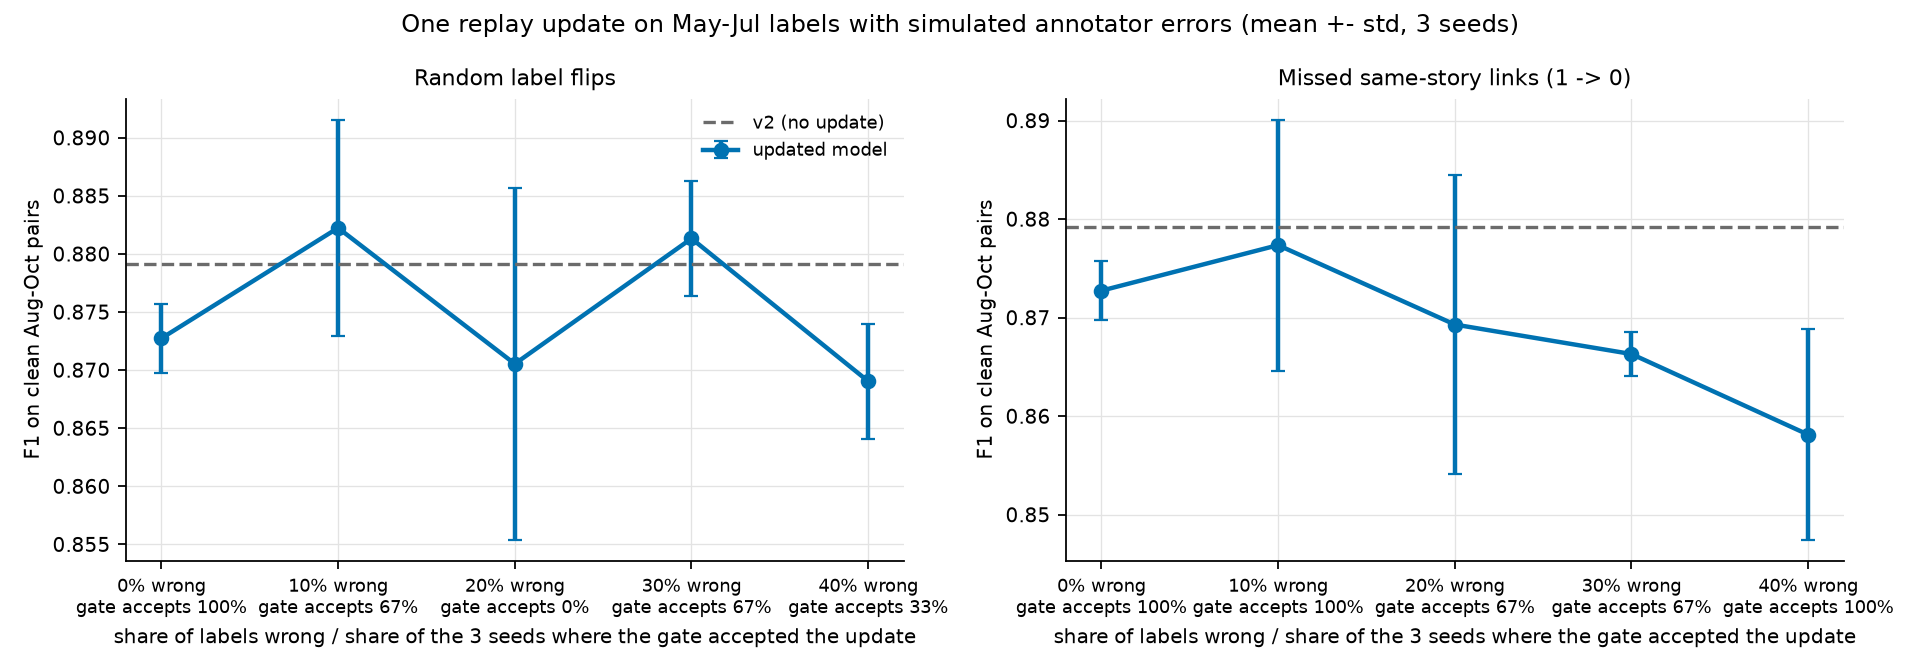

In [10]:
display(Image(OUT / 'figures' / 'C_bad_labels.png'))

## D. Efficiency

Update time and peak memory (training on the laptop GPU, MPS) and CPU latency per front page (same as Milestones 2 and 3).
On a Mac, the GPU memory is what the MPS driver has allocated (it includes its cache), so it is higher than what the model needs.

In [11]:
eff = summary[summary.update_min_mean.notna()][['part', 'strategy', 'update_min_mean', 'update_min_total_mean', 'peak_ram_mb', 'peak_gpu_mb']].copy()
eff['update_sec_per_update'] = eff.pop('update_min_mean') * 60
eff

,part,strategy,update_min_total_mean,peak_ram_mb,peak_gpu_mb,update_sec_per_update
1,A,replay + gate (monthly),0.409,5397.889,12934.988,4.907
4,B,"fine-tune, no replay",0.273,5290.148,12634.751,3.272
5,B,replay + gate (monthly),0.407,4904.452,11410.588,4.882
6,B,replay + gate (when triggered),0.253,5309.383,13161.153,4.531
7,B,full retrain (monthly),10.089,4963.516,10728.407,121.063


In [12]:
pd.read_csv(OUT / 'latency_size.csv')

,model,p50_ms,p90_ms,n_pages,model_mb
0,v2 (start),25.962,29.746,200,487.727
1,v2.4 (A_always_replay_6450),25.858,29.238,200,487.727
2,v2.1 (B_always_replay_6450),26.211,30.220,200,487.727


## Results summary

- **Real data:** no trigger fired, and updating every month did not help (F1 0.898 vs 0.895, card ARI a bit lower). So the
  triggers saved us from useless updates.
- **Simulated drift:** without updates, F1 drops from 0.906 (May) to 0.823 (Oct, 30% typos). Replay + gate every month
  keeps it at 0.861 ± 0.015 in October. Full retrain gets 0.874, but takes about 2 min per update instead of about 5 s
  (25 times more). Fine-tuning without replay or only when triggered helps less (0.842 and 0.845).
- **Forgetting:** F1 on the old validation data stayed between 0.875 and 0.883 (start 0.878) for every strategy. The
  updates are small (2 epochs, a few hundred pairs), so we could not show forgetting here, even without replay.
- **Gate:** it rejected 2 to 4 of the 5 monthly updates per seed. Most rejections were in Aug and Sep, where the new
  model really was worse on the holdout (0.864 to 0.848 and 0.854 to 0.834, mean over seeds), so the gate kept the
  better model. The holdout is small (85 pairs on average), so some decisions are still noisy.
- **Bad labels:** random wrong labels barely matter, but systematic ones (missed same-story links) lower F1 from 0.873
  to 0.858 at 40%, and the gate still accepted every one of these updates. The gate checks against labels from the
  same annotators, so it cannot see this kind of mistake.
- **Latency and size** do not change after an update (about 26 ms per page on CPU, 488 MB), because the model architecture stays the same.